# Olist reviews: data preparation and split

Part 1 of a project comparing a TF-IDF baseline with a fine-tuned BERTimbau for Portuguese review sentiment.

This notebook turns the raw Olist reviews into a clean, labelled dataset and a fixed
train / validation / test split that every later model uses:

1. Keep reviews that have text (title and/or message).
2. Normalize whitespace and remove duplicates, including identical texts, to avoid train/test leakage.
3. Map star ratings to sentiment: 1-2 → negative, 3 → neutral, 4-5 → positive.
4. Stratified 80 / 10 / 10 split, saved as `train.csv`, `validation.csv`, `test.csv`.

**Input:** *Brazilian E-Commerce Public Dataset by Olist* (add it with *Add Input*).

## Setup

In [1]:
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

# Kaggle keeps the notebook's outputs in /kaggle/working. Locally, use the current folder.
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")

## Load

In [2]:
INPUT_DIR = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path(".")
reviews_file = next(INPUT_DIR.rglob("olist_order_reviews_dataset.csv"), None)

if reviews_file is None:
    raise FileNotFoundError(
        "olist_order_reviews_dataset.csv not found. "
        "Add the Olist dataset with 'Add Input' in the right-hand panel."
    )

print("Reading:", reviews_file)
df = pd.read_csv(reviews_file)
print(f"{len(df):,} rows, {df.shape[1]} columns")
df.head()

Reading: /kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv
99,224 rows, 7 columns


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [3]:
df.info()
print()
print("Missing values per column:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB

Missing values per column:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


## Build the text field

Most reviews have only a star rating and no comment; those carry no text to classify and are dropped.
Title and message are joined (`title. message`), since short titles such as "Péssimo" or "Recomendo" often carry the sentiment.

In [4]:
def clean(series: pd.Series) -> pd.Series:
    """Collapse repeated whitespace and line breaks into a single space and trim the ends."""
    return series.fillna("").str.replace(r"\s+", " ", regex=True).str.strip()

title = clean(df["review_comment_title"])
message = clean(df["review_comment_message"])

# With both a title AND a message: "title. message". Otherwise, whichever exists (the other is "").
has_both = (title != "") & (message != "")
df["text"] = (title + ". " + message).where(has_both, title + message)

before = len(df)
df = df[df["text"] != ""].copy()
print(f"With text: {len(df):,} of {before:,} reviews ({len(df) / before:.0%})")

With text: 42,687 of 99,224 reviews (43%)


## Remove duplicates

- The same `review_id` can appear once per linked order.
- Identical texts ("Muito bom", "Recomendo") appear hundreds of times. Left in, the same text would land in
  both train and test and inflate test scores (leakage). Texts are compared case-insensitively and the first occurrence is kept.

Side effect: identical short texts with different ratings collapse to one example, which removes some short positive reviews.

In [5]:
n0 = len(df)
df = df.drop_duplicates(subset="review_id")
n1 = len(df)

df["text_norm"] = df["text"].str.lower()
df = df.drop_duplicates(subset="text_norm").drop(columns="text_norm")
n2 = len(df)

print(f"Repeated review_id removed: {n0 - n1:,}")
print(f"Repeated text removed:      {n1 - n2:,}")
print(f"Remaining: {n2:,} reviews")

Repeated review_id removed: 317
Repeated text removed:      5,901
Remaining: 36,469 reviews


## Labels

`label_id` follows the order negative=0, neutral=1, positive=2. The fine-tuned model reuses this mapping as `id2label`.

In [6]:
RATING_TO_LABEL = {1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"}
LABELS = ["negative", "neutral", "positive"]
LABEL_TO_ID = {label: i for i, label in enumerate(LABELS)}  # {"negative": 0, "neutral": 1, "positive": 2}

df["label"] = df["review_score"].map(RATING_TO_LABEL)
df["label_id"] = df["label"].map(LABEL_TO_ID)

assert df["label"].notna().all(), "Found a rating outside 1-5"
print(LABEL_TO_ID)

{'negative': 0, 'neutral': 1, 'positive': 2}


### Class distribution

The classes are imbalanced, with neutral the smallest. A majority-class guess already gets high accuracy,
so the project reports **macro-F1** (the unweighted mean of per-class F1) as the main metric.

          reviews  percent
label                     
negative    10430     28.6
neutral      3264      9.0
positive    22775     62.5

Distribution by rating:
review_score
1     8371
2     2059
3     3264
4     5143
5    17632
Name: count, dtype: int64


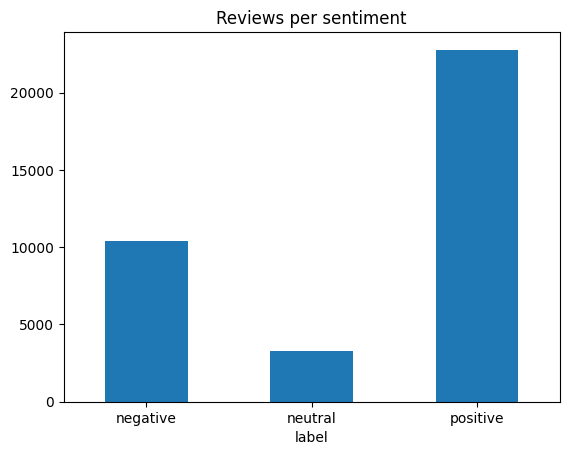

In [7]:
counts = df["label"].value_counts().reindex(LABELS)
summary = pd.DataFrame({"reviews": counts, "percent": (counts / len(df) * 100).round(1)})
print(summary)
print()
print("Distribution by rating:")
print(df["review_score"].value_counts().sort_index())

summary["reviews"].plot.bar(title="Reviews per sentiment", rot=0);

### Text length

Guides the transformer's `max_length`: if nearly all reviews are short, 128 tokens is enough.

In [8]:
words = df["text"].str.split().str.len()
print(words.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))
print()
print("Examples per class:")
for label in LABELS:
    sample = df.loc[df["label"] == label, "text"].sample(2, random_state=SEED)
    for t in sample:
        print(f"[{label}] {t[:150]}")

count    36469.0
mean        13.3
std          9.5
min          1.0
50%         10.0
90%         29.0
95%         34.0
99%         38.0
max         48.0
Name: text, dtype: float64

Examples per class:
[negative] O produto e um abridor que simplesmente nao abre! Pasmem! Eu coloquei na parede e depois fomos tentar abrir uma garrafa e a tampa da garrafa simplesme
[negative] Solicito a troca do produto Recebi o produto errado Solicito a troca até dia 8/2/17, Pois o produto é presente de aniversário de meu filho que será di
[neutral] sempre compro com voces,porem dessa vez o produto que comprei deu problema no prazo de entrega
[neutral] O produto esquenta bastante, instruções para instalação em inglês, tive dificuldades na instalação.
[positive] Faz o que oferece por um preço acessível
[positive] Uahlll! Recebi minha compra 30 dias antes do prazo definido! Adorei comprar da targaryen!


## Stratified 80 / 10 / 10 split

Stratification keeps the class shares equal across splits, which matters for the small neutral class.

In [9]:
train, rest = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
validation, test = train_test_split(rest, test_size=0.5, stratify=rest["label"], random_state=SEED)

splits = {"train": train, "validation": validation, "test": test}
for name, part in splits.items():
    print(f"{name:>10}: {len(part):>6,} reviews")

     train: 29,175 reviews
validation:  3,647 reviews
      test:  3,647 reviews


In [10]:
shares = pd.DataFrame(
    {name: part["label"].value_counts(normalize=True).reindex(LABELS) for name, part in splits.items()}
)
print((shares * 100).round(1))

ids = {name: set(part["review_id"]) for name, part in splits.items()}
assert not ids["train"] & ids["validation"]
assert not ids["train"] & ids["test"]
assert not ids["validation"] & ids["test"]
print("\nNo review is shared between splits.")

          train  validation  test
label                            
negative   28.6        28.6  28.6
neutral     8.9         8.9   9.0
positive   62.5        62.5  62.4

No review is shared between splits.


## Save

In [11]:
COLUMNS = ["review_id", "text", "review_score", "label", "label_id"]

for name, part in splits.items():
    path = OUTPUT_DIR / f"{name}.csv"
    part[COLUMNS].to_csv(path, index=False)
    print("Saved:", path)

Saved: /kaggle/working/train.csv
Saved: /kaggle/working/validation.csv
Saved: /kaggle/working/test.csv


## Next steps

The baseline and BERTimbau notebooks read these files via *Add Input → Your Work → this notebook*,
so every model is trained and evaluated on exactly the same examples.

## Data and license

Olist, *Brazilian E-Commerce Public Dataset by Olist*, Kaggle, CC BY-NC-SA 4.0.